In [1]:
# CELL 1: imports and setup
import os, hashlib, random, copy
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cuda


Number of classes: 10
Classes: ['akara', 'amala', 'efo_riro', 'egusi_soup', 'fried_rice', 'jollof_rice', 'moi_moi', 'pounded_yam', 'puff_puff', 'suya']

Raw images: 500
Corrupted: 0
Cross-class duplicate groups dropped: 0
Clean images kept: 491


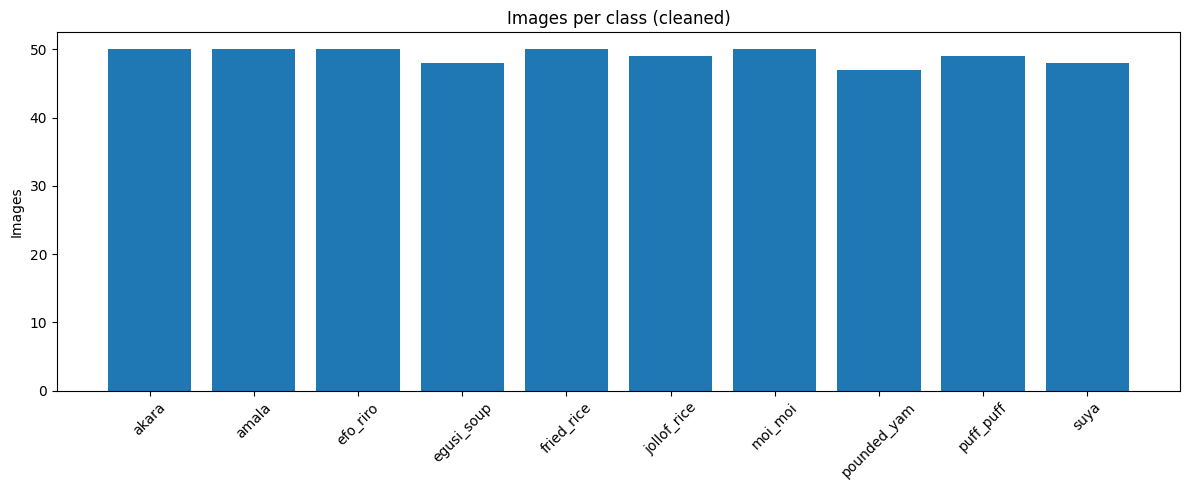

In [2]:
# CELL 2: scan the dataset, remove corrupt files and duplicates automatically
data_path = "/kaggle/input/datasets/foyinsolaodekunle/nigerian-food-dataset/Nigerian_Food_Dataset"
EXTS = (".jpg", ".jpeg", ".png", ".webp")
 
class_names = sorted(d for d in os.listdir(data_path)
                     if os.path.isdir(os.path.join(data_path, d)))
class_to_idx = {c: i for i, c in enumerate(class_names)}
print("Number of classes:", len(class_names))
print("Classes:", class_names)
 
corrupted = []
hash_to_items = defaultdict(list)   # md5 -> [(path, label), ...]
raw_counts = Counter()
 
for c in class_names:
    folder = os.path.join(data_path, c)
    for f in sorted(os.listdir(folder)):
        if not f.lower().endswith(EXTS):
            continue
        p = os.path.join(folder, f)
        raw_counts[c] += 1
        try:
            with Image.open(p) as img:
                img.verify()
        except Exception:
            corrupted.append(p)
            continue
        with open(p, "rb") as fh:
            h = hashlib.md5(fh.read()).hexdigest()
        hash_to_items[h].append((p, class_to_idx[c]))
 
samples = []          # final cleaned list of (path, label)
label_conflicts = 0
for h, items in hash_to_items.items():
    if len({lbl for _, lbl in items}) > 1:   # same image under different classes: drop it
        label_conflicts += 1
        continue
    samples.append(items[0])                 # keep one copy of within-class duplicates
 
print("\nRaw images:", sum(raw_counts.values()))
print("Corrupted:", len(corrupted))
print("Cross-class duplicate groups dropped:", label_conflicts)
print("Clean images kept:", len(samples))
 
clean_counts = Counter(class_names[lbl] for _, lbl in samples)
plt.figure(figsize=(12, 5))
plt.bar(clean_counts.keys(), clean_counts.values())
plt.xticks(rotation=45); plt.ylabel("Images"); plt.title("Images per class (cleaned)")
plt.tight_layout(); plt.show()

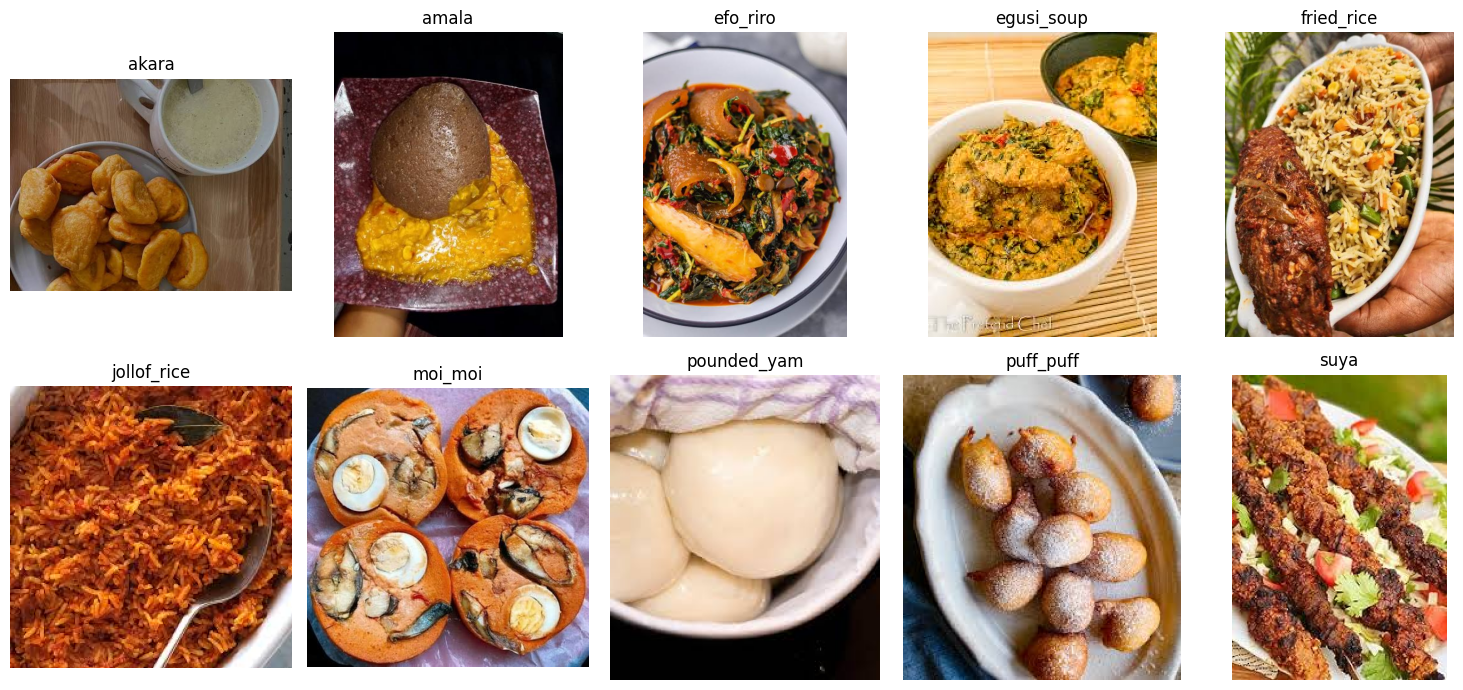

In [3]:

# CELL 3: quick look at the data
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, c in zip(axes.flat, class_names):
    p, _ = random.choice([s for s in samples if class_names[s[1]] == c])
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

In [4]:
# CELL 4: stratified split (70% train / 15% val / 15% test)
paths = [p for p, _ in samples]
labels = [l for _, l in samples]

train_p, temp_p, train_y, temp_y = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)

print("Train / Val / Test:", len(train_p), len(val_p), len(test_p))

Train / Val / Test: 343 74 74


In [5]:
IMG_SIZE = 288
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
 
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25),
])
eval_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
 
class FoodDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]
 
BATCH = 16   # smaller batch because images are bigger; lower to 8 if you hit an out-of-memory error
train_loader = DataLoader(FoodDataset(train_p, train_y, train_tf),
                          batch_size=BATCH, shuffle=True, num_workers=2)
val_loader = DataLoader(FoodDataset(val_p, val_y, eval_tf),
                        batch_size=BATCH, num_workers=2)
test_loader = DataLoader(FoodDataset(test_p, test_y, eval_tf),
                         batch_size=BATCH, num_workers=2)


In [6]:
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
in_features = model.classifier[2].in_features
model.classifier = nn.Sequential(
    model.classifier[0],            # LayerNorm
    model.classifier[1],            # Flatten
    nn.Dropout(0.3),
    nn.Linear(in_features, len(class_names)),
)
for p in model.features.parameters():     # phase 1: freeze the backbone
    p.requires_grad = False
model = model.to(device)
 
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 203MB/s] 


In [7]:
# CELL 7: training helpers
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n
 
def fit(model, epochs, lr, patience=5):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
    best_acc, best_state, wait = -1.0, None, 0
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, optimizer)
        vl, va = run_epoch(model, val_loader)
        scheduler.step(vl)
        print(f"Epoch {ep:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
        if va > best_acc:
            best_acc, best_state, wait = va, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break
    model.load_state_dict(best_state)
    print(f"Best val acc: {best_acc:.3f}")
 
 

In [8]:
# CELL 8: phase 1 - train the new head only
fit(model, epochs=12, lr=1e-3)

Epoch 01 | train loss 2.030 acc 0.347 | val loss 1.599 acc 0.811
Epoch 02 | train loss 1.434 acc 0.784 | val loss 1.204 acc 0.892
Epoch 03 | train loss 1.092 acc 0.886 | val loss 1.014 acc 0.905
Epoch 04 | train loss 0.943 acc 0.924 | val loss 0.921 acc 0.932
Epoch 05 | train loss 0.835 acc 0.953 | val loss 0.885 acc 0.919
Epoch 06 | train loss 0.785 acc 0.953 | val loss 0.856 acc 0.932
Epoch 07 | train loss 0.774 acc 0.953 | val loss 0.839 acc 0.905
Epoch 08 | train loss 0.743 acc 0.968 | val loss 0.811 acc 0.946
Epoch 09 | train loss 0.706 acc 0.968 | val loss 0.818 acc 0.892
Epoch 10 | train loss 0.700 acc 0.983 | val loss 0.805 acc 0.932
Epoch 11 | train loss 0.690 acc 0.971 | val loss 0.802 acc 0.946
Epoch 12 | train loss 0.701 acc 0.974 | val loss 0.800 acc 0.946
Best val acc: 0.946


In [9]:
# CELL 9: phase 2 - fine-tune the upper layers at a low learning rate

for p in model.features[5:].parameters():
    p.requires_grad = True
fit(model, epochs=20, lr=5e-5, patience=6)


Epoch 01 | train loss 0.680 acc 0.985 | val loss 0.753 acc 0.946
Epoch 02 | train loss 0.628 acc 0.991 | val loss 0.746 acc 0.959
Epoch 03 | train loss 0.629 acc 0.985 | val loss 0.747 acc 0.946
Epoch 04 | train loss 0.596 acc 0.997 | val loss 0.728 acc 0.946
Epoch 05 | train loss 0.591 acc 0.994 | val loss 0.728 acc 0.946
Epoch 06 | train loss 0.584 acc 0.991 | val loss 0.711 acc 0.932
Epoch 07 | train loss 0.573 acc 0.994 | val loss 0.728 acc 0.932
Epoch 08 | train loss 0.564 acc 0.997 | val loss 0.701 acc 0.973
Epoch 09 | train loss 0.560 acc 0.997 | val loss 0.686 acc 0.946
Epoch 10 | train loss 0.551 acc 1.000 | val loss 0.692 acc 0.946
Epoch 11 | train loss 0.557 acc 0.997 | val loss 0.687 acc 0.959
Epoch 12 | train loss 0.552 acc 1.000 | val loss 0.680 acc 0.959
Epoch 13 | train loss 0.545 acc 0.997 | val loss 0.673 acc 0.959
Epoch 14 | train loss 0.543 acc 1.000 | val loss 0.674 acc 0.959
Early stopping.
Best val acc: 0.973


Test accuracy: 0.9594594594594594
              precision    recall  f1-score   support

       akara       0.88      1.00      0.93         7
       amala       1.00      1.00      1.00         7
    efo_riro       0.89      1.00      0.94         8
  egusi_soup       1.00      1.00      1.00         7
  fried_rice       1.00      1.00      1.00         8
 jollof_rice       1.00      0.75      0.86         8
     moi_moi       1.00      1.00      1.00         7
 pounded_yam       1.00      1.00      1.00         7
   puff_puff       0.88      0.88      0.88         8
        suya       1.00      1.00      1.00         7

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.96      0.96      0.96        74



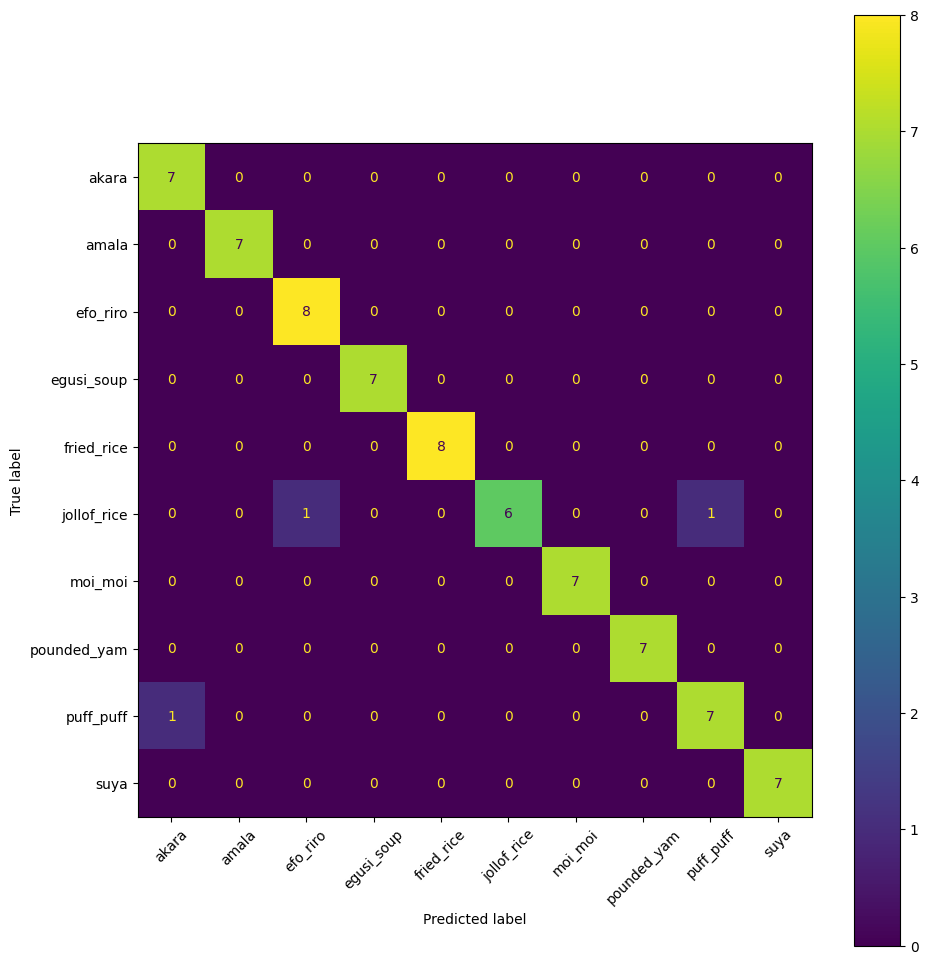

In [10]:
# CELL 10: evaluate on the untouched test set
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred.extend(out.argmax(1).cpu().tolist())
        y_true.extend(y.tolist())

print("Test accuracy:", np.mean(np.array(y_true) == np.array(y_pred)))
print(classification_report(y_true, y_pred, target_names=class_names))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=class_names).plot(ax=ax, xticks_rotation=45)
plt.tight_layout(); plt.show()


In [11]:
#CELL 10b: test-time augmentation (average original + flipped image)
model.eval()
y_true_tta, y_pred_tta = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        probs = torch.softmax(model(x), 1) + torch.softmax(model(torch.flip(x, dims=[3])), 1)
        y_pred_tta.extend(probs.argmax(1).cpu().tolist())
        y_true_tta.extend(y.tolist())
 
print("Test accuracy with TTA:", np.mean(np.array(y_true_tta) == np.array(y_pred_tta)))

Test accuracy with TTA: 0.9594594594594594


Most common mistakes (true -> predicted):
  puff_puff    -> akara        x1
  jollof_rice  -> efo_riro     x1
  jollof_rice  -> puff_puff    x1


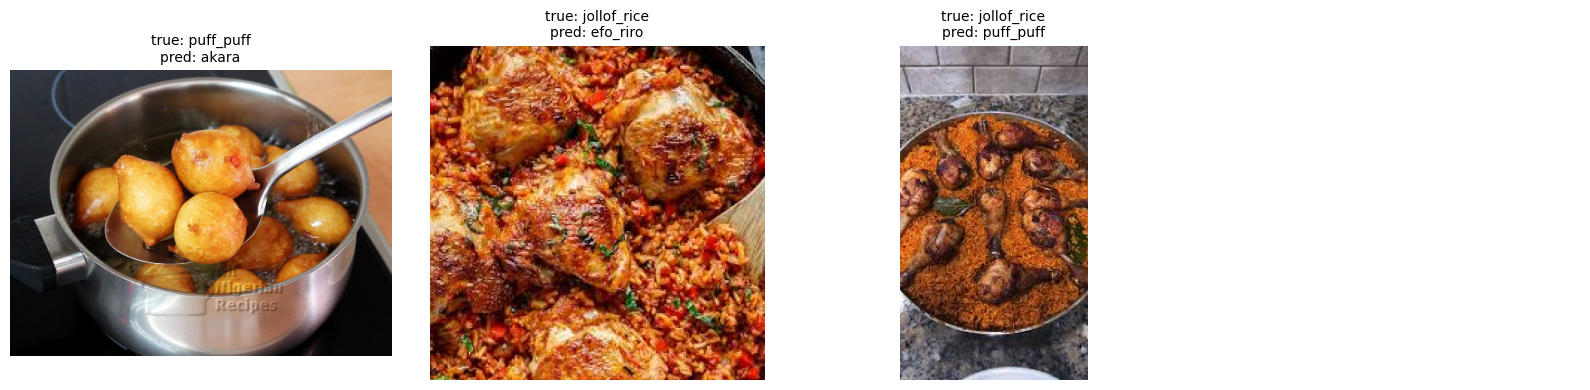

In [12]:
# CELL 13: most common confusions (true class -> predicted class)
from collections import Counter

pairs = Counter((class_names[t], class_names[p])
                for t, p in zip(y_true, y_pred) if t != p)
print("Most common mistakes (true -> predicted):")
for (t, p), n in pairs.most_common():
    print(f"  {t:12s} -> {p:12s} x{n}")


# CELL 14: view every misclassified test image
wrong = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p]
cols = 4
rows = (len(wrong) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
for ax in np.array(axes).flat:
    ax.axis("off")
for ax, i in zip(np.array(axes).flat, wrong):
    ax.imshow(Image.open(test_p[i]).convert("RGB"))
    ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}", fontsize=10)
plt.tight_layout()
plt.savefig("/kaggle/working/misclassified.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# CELL 11: save the model
torch.save({"state_dict": model.state_dict(), "class_names": class_names},
           "/kaggle/working/nigerian_food_classifier.pt")

In [14]:
# CELL 12: predict a single image (use later for demos)
def predict(image_path, top_k=3):
    model.eval()
    img = eval_tf(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(img), dim=1)[0]
    top = probs.topk(top_k)
    return [(class_names[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

# Example: print(predict(test_p[0]))

In [15]:
ckpt = torch.load("/kaggle/working/nigerian_food_classifier.pt", map_location="cpu")
ckpt["state_dict"] = {k: v.half() if v.is_floating_point() else v
                      for k, v in ckpt["state_dict"].items()}
torch.save(ckpt, "/kaggle/working/nigerian_food_classifier_fp16.pt")

In [16]:
print(predict(test_p[0]))

[('moi_moi', 0.901), ('amala', 0.025), ('akara', 0.019)]
